# Duck data, spatial joins, and a year of seasonal change

**A visual tour of [vgi-ducks](https://github.com/Query-farm/vgi-ducks) with DuckDB SQL.**

Start with the duck catalog, intersect seasonal ranges with locations, then turn a
polygon into a weekly abundance curve and a peak-week summary. The queries run
against the published **v0.1.0 TypeScript worker** through VGI. Python handles
notebook display and plotting; the analysis stays in SQL.

**No personal API key is needed.** The catalog contains real duck taxonomy. The
migration demonstration uses Cornell's public **Yellow-bellied Sapsucker** sample
for **2023**, at **27 km** resolution. It is a non-duck species, and its weekly
raster contains predictions only in Michigan. Every migration chart is labeled
accordingly. These are modeled seasonal patterns, not individual tracks or a
current migration forecast.


## Run it, or just read it

GitHub displays the saved tables and PNG figures below. To rerun every cell from
the repository root, with [uv](https://docs.astral.sh/uv/) installed:

```sh
uv run --no-project --python 3.12 --with-requirements notebooks/requirements.txt python scripts/render_notebook.py
```

For an interactive editing session:

```sh
uv run --no-project --python 3.12 --with-requirements notebooks/requirements.txt jupyter lab notebooks/spatial-migration.ipynb
```

Select the **Python 3** kernel, then **Restart Kernel and Run All Cells**. This
notebook uses JupySQL's `%%sql` cells with stock DuckDB **2.0.0**. The first run
needs internet access to download signed extensions, the pinned worker release,
and Cornell's public sample. The published executable needs no Bun installation.
The final cell closes the database; restart the kernel before running again.


In [1]:
import json
import os
import tempfile

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from pathlib import Path

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from shapely import orient_polygons
from shapely.geometry import shape
from shapely.plotting import plot_polygon
from sqlalchemy import create_engine

assert duckdb.__version__ == "2.0.0", "Use the pinned notebook requirements."
overrides = ("DUCKS_EBIRD_BASE_URL", "DUCKS_STATUS_BASE_URL", "DUCKS_STATUS_SAMPLE_BASE_URL")
assert not any(os.environ.get(key) for key in overrides), "Unset test endpoint overrides before running."

extension_directory = tempfile.TemporaryDirectory(prefix="vgi-ducks-demo-")
engine = create_engine("duckdb:///:memory:", connect_args={"config": {
    "extension_repository_directory": str(Path(extension_directory.name) / "repositories"),
    "extension_directory": str(Path(extension_directory.name) / "extensions"),
}})
%load_ext sql
%sql engine --alias ducks_demo
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = 0
%config SqlMagic.displaycon = False
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")

# Keep standalone figures beside the notebook for README previews and reuse.
notebook_dir = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
image_dir = notebook_dir / "images"
image_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 14,
    "axes.labelcolor": "#334155", "text.color": "#0f172a",
    "xtick.color": "#475569", "ytick.color": "#475569",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#cbd5e1", "grid.color": "#e2e8f0",
})
TEAL, GOLD, SLATE = "#087f8c", "#c78b20", "#334155"

def show_chart(fig, filename):
    fig.savefig(image_dir / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

print("DuckDB", duckdb.__version__, "| VGI worker release v0.1.0 | public data only")


DuckDB 2.0.0 | VGI worker release v0.1.0 | public data only


In [2]:
%%sql
SET allow_extension_repositories = 'allowed';
CREATE EXTENSION REPOSITORY IF NOT EXISTS query_farm
  WITH PREFIX 'https://duckdb-extensions.query.farm';
INSTALL vgi FROM query_farm;
LOAD vgi FROM query_farm;
INSTALL spatial FROM core;
LOAD spatial;
INSTALL icu FROM core;
LOAD icu;
SET TimeZone = 'UTC';
SET geometry_always_xy = true;

ATTACH 'ducks' (
  TYPE vgi,
  LOCATION 'github-auto://Query-farm/vgi-ducks@v0.1.0'
);

SELECT extension_name, extension_version
FROM duckdb_extensions()
WHERE extension_name IN ('vgi', 'spatial') AND loaded
ORDER BY extension_name;


,extension_name,extension_version
0,spatial,a3dbcd1781
1,vgi,e75482339d


## 1. Start with a duck question

**Which genera contain the most extant duck species in this catalog?**

The bundled eBird 2026 taxonomy makes this an offline SQL aggregation after the
worker is attached. Extinct taxa are explicitly flagged. This is species richness
within the worker's documented duck scope, not a count of individual birds.


In [3]:
%%sql
SELECT taxonomy_version,
       count(*) AS catalog_species,
       count(*) FILTER (WHERE NOT extinct) AS extant_species,
       count(*) FILTER (WHERE extinct) AS extinct_species
FROM ducks.main.species
GROUP BY taxonomy_version;


,taxonomy_version,catalog_species,extant_species,extinct_species
0,2026,140,131,9


In [4]:
%%sql genera <<
SELECT genus, count(*) AS extant_species
FROM ducks.main.species
WHERE NOT extinct
GROUP BY genus
ORDER BY extant_species DESC, genus
LIMIT 10;


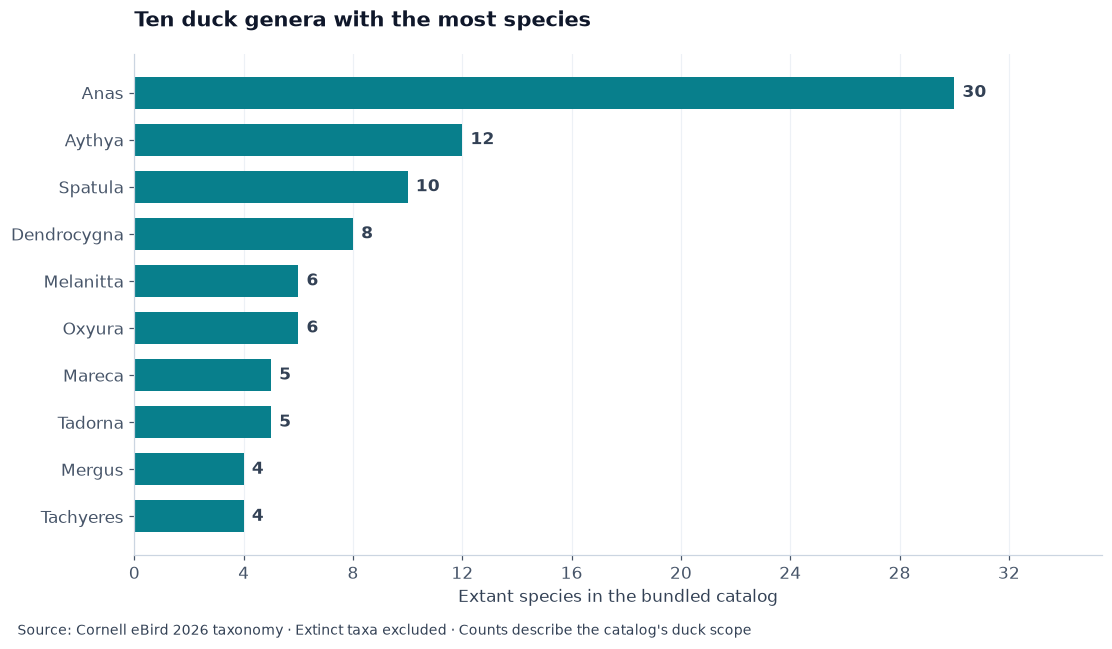

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.barh(genera.genus, genera.extant_species, color=TEAL, height=0.68)
ax.invert_yaxis()
ax.set_xlim(0, genera.extant_species.max() * 1.18)
ax.set_xlabel("Extant species in the bundled catalog")
ax.set_title("Ten duck genera with the most species", loc="left", weight="bold", pad=18)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="x", alpha=0.6)
ax.set_axisbelow(True)
for i, value in enumerate(genera.extant_species):
    ax.text(value + 0.3, i, str(value), va="center", weight="bold", color=SLATE)
fig.text(0.01, -0.04, "Source: Cornell eBird 2026 taxonomy · Extinct taxa excluded · Counts describe the catalog's duck scope", fontsize=9, color=SLATE)
show_chart(fig, "duck-genera.png")


## 2. Bring seasonal ranges into a spatial query

**Where do seasonal model ranges overlap our study window?**

`seasonal_ranges` reads Cornell's GeoPackage and returns ordinary WKB.
`ST_GeomFromWKB` turns it into a DuckDB Spatial geometry. Materialize the download
once, then use ordinary spatial SQL. The rectangle below is an illustrative study
window around Michigan, **not an administrative boundary or official wetland**.
All WGS84 coordinates use longitude first, latitude second.

From this point onward the species is **Yellow-bellied Sapsucker**, using the
public sample, not a duck. Polygon boundaries describe modeled ranges. They do
not establish individual migration corridors.


In [6]:
%%sql
SET VARIABLE study_region = 'POLYGON((-90 41,-82 41,-82 49,-90 49,-90 41))';

CREATE TEMP TABLE ranges AS
SELECT * FROM ducks.main.seasonal_ranges('yebsap-example', data_year := 2023);

SELECT common_name, season, start_date, end_date, wraps_year
FROM ranges
ORDER BY start_date;


,common_name,season,start_date,end_date,wraps_year
0,Yellow-bellied Sapsucker,prebreeding_migration,2023-03-15,2023-05-10,False
1,Yellow-bellied Sapsucker,breeding,2023-05-17,2023-08-16,False
2,Yellow-bellied Sapsucker,postbreeding_migration,2023-08-23,2023-11-15,False
3,Yellow-bellied Sapsucker,nonbreeding,2023-11-22,2023-03-08,True


In [7]:
%%sql range_map <<
SELECT season, start_date, end_date,
       ST_AsGeoJSON(ST_Intersection(
         ST_GeomFromWKB(geometry_wkb),
         ST_GeomFromText('POLYGON((-92 40,-80 40,-80 50,-92 50,-92 40))')
       )) AS geometry_json
FROM ranges;


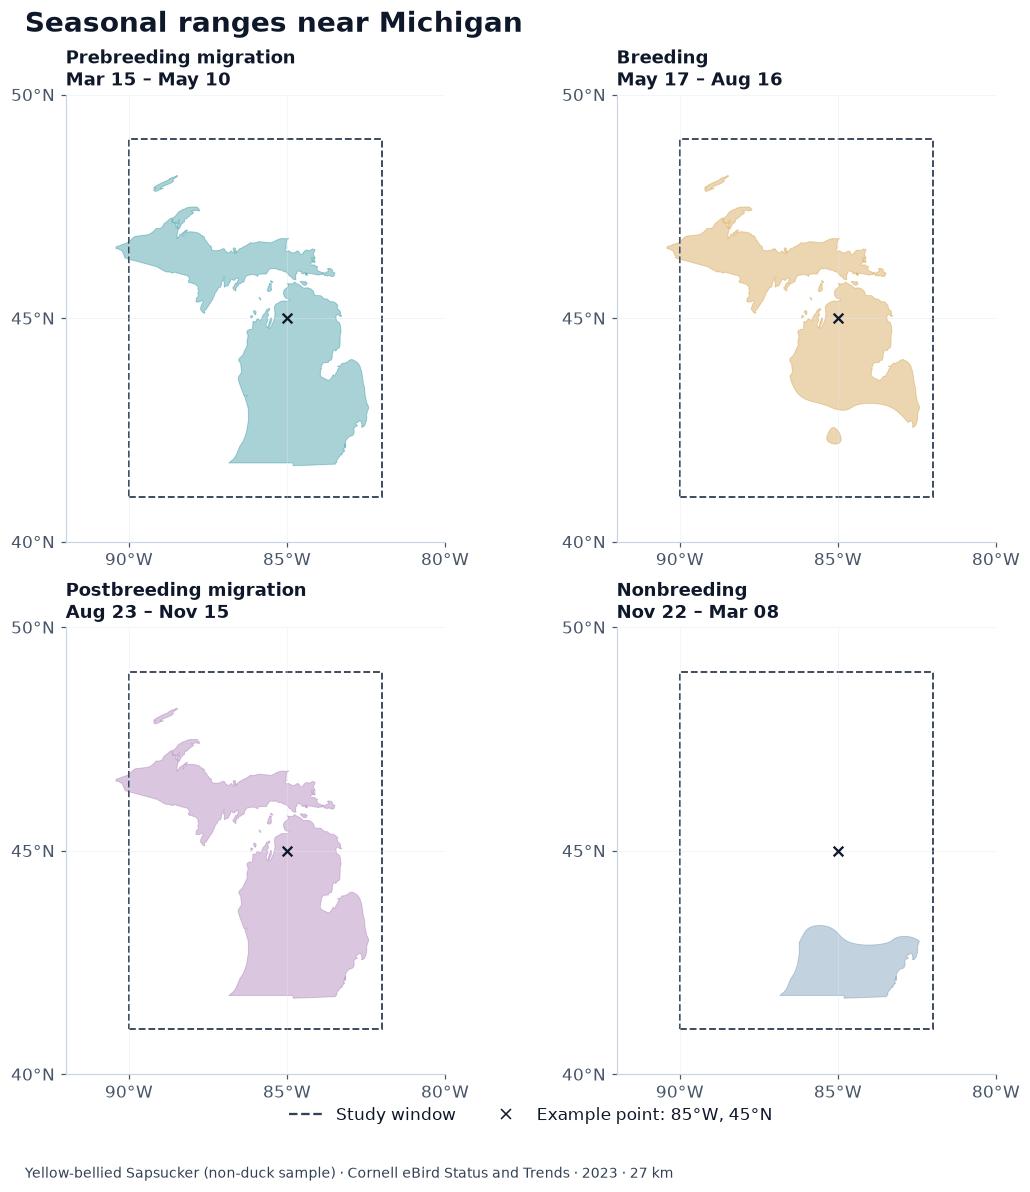

In [8]:
seasons = [
    ("prebreeding_migration", "Prebreeding migration", "#087f8c"),
    ("breeding", "Breeding", "#c78b20"),
    ("postbreeding_migration", "Postbreeding migration", "#9661a6"),
    ("nonbreeding", "Nonbreeding", "#527fa6"),
]

def draw_polygons(ax, geometry, color):
    if geometry.is_empty:
        return
    if geometry.geom_type == "Polygon":
        plot_polygon(orient_polygons(geometry), ax=ax, add_points=False,
                     facecolor=color, edgecolor=color, alpha=0.35, linewidth=0.6)
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            draw_polygons(ax, part, color)

fig, axes = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")
for ax, (season, title, color) in zip(axes.flat, seasons):
    row = range_map.loc[range_map.season == season].iloc[0]
    draw_polygons(ax, shape(json.loads(row.geometry_json)), color)
    ax.add_patch(Rectangle((-90, 41), 8, 8, fill=False, edgecolor=SLATE,
                           linewidth=1.2, linestyle="--"))
    ax.scatter([-85], [45], marker="x", color="#0f172a", s=40, linewidth=1.5, zorder=5)
    ax.set_xlim(-92, -80)
    ax.set_ylim(40, 50)
    ax.set_aspect(1 / 0.7071)  # Approximate longitude scaling around 45 degrees N.
    ax.set_xticks([-90, -85, -80])
    ax.set_xticklabels(["90°W", "85°W", "80°W"])
    ax.set_yticks([40, 45, 50])
    ax.set_yticklabels(["40°N", "45°N", "50°N"])
    ax.grid(alpha=0.5, linewidth=0.5)
    dates = f"{pd.Timestamp(row.start_date):%b %d} – {pd.Timestamp(row.end_date):%b %d}"
    ax.set_title(f"{title}\n{dates}", loc="left", fontsize=12, weight="bold")
fig.suptitle("Seasonal ranges near Michigan", fontsize=18, weight="bold", x=0.04, ha="left")
fig.legend(handles=[
    Line2D([0], [0], color=SLATE, linestyle="--", label="Study window"),
    Line2D([0], [0], color="#0f172a", marker="x", linestyle="none", label="Example point: 85°W, 45°N"),
], loc="lower center", bbox_to_anchor=(0.5, -0.03), ncol=2, frameon=False)
fig.text(0.04, -0.065, "Yellow-bellied Sapsucker (non-duck sample) · Cornell eBird Status and Trends · 2023 · 27 km", fontsize=9, color=SLATE)
show_chart(fig, "seasonal-ranges.png")


### Ask which seasons intersect a location

The cross on each map is the same point. A spatial join finds its overlapping
seasons, together with two illustrative city-center coordinates. Replace these
points with your own polygons to compare wetlands, refuges, or other areas.
These coordinates are example query locations, not confirmed bird sightings.


In [9]:
%%sql
WITH sites(name, longitude, latitude) AS (
  VALUES ('Map example point', -85.0, 45.0),
         ('Detroit city center', -83.0458, 42.3314),
         ('Marquette city center', -87.3954, 46.5436)
)
SELECT s.name,
       string_agg(r.season, ', ' ORDER BY r.season) AS intersecting_seasons
FROM sites AS s
LEFT JOIN ranges AS r
  ON ST_Intersects(ST_GeomFromWKB(r.geometry_wkb), ST_Point(s.longitude, s.latitude))
GROUP BY s.name
ORDER BY s.name;


,name,intersecting_seasons
0,Detroit city center,NaN
1,Map example point,"breeding, postbreeding_migration, prebreeding_..."
2,Marquette city center,"breeding, postbreeding_migration, prebreeding_..."


## 3. Turn a polygon into a weekly curve

**When is modeled relative abundance highest inside this region?**

`weekly_abundance` reads the weekly GeoTIFF, transforms native Equal Earth cell
centers to WGS84, and selects those strictly inside the polygon. Holes and
multipart regions are supported. The mean gives equal weight to modeled cells;
it is not an exact area-clipped mean or a regional bird population estimate.

Relative abundance is expected birds per standardized **one-hour, two-kilometer
checklist** under the model's observation conditions. True zero remains zero.
Missing predictions are excluded from the mean and reported in the coverage
columns. Keep those columns alongside the curve.


In [10]:
%%sql
CREATE TEMP TABLE weekly AS
SELECT * FROM ducks.main.weekly_abundance(
  'yebsap-example', getvariable('study_region'), data_year := 2023
);

SELECT count(*) AS modeled_weeks,
       min(week_date) AS first_week,
       max(week_date) AS last_week,
       min(selected_cell_count) AS selected_cell_centers,
       min(modeled_cell_count) AS minimum_modeled_cells,
       max(modeled_cell_count) AS maximum_modeled_cells
FROM weekly;


,modeled_weeks,first_week,last_week,selected_cell_centers,minimum_modeled_cells,maximum_modeled_cells
0,52,2023-01-04,2023-12-27,779,288,289


In [11]:
%%sql curve <<
SELECT week_date::DATE AS week_date, mean_relative_abundance,
       selected_cell_count, modeled_cell_count, coverage_fraction
FROM weekly
ORDER BY week_date;


### Ask for peak weeks directly

`migration_calendar` returns every week tied for the highest positive mean, with
coverage retained. An all-zero or entirely unmodeled series has no peak rows.
A peak can reflect breeding or winter residence; it is not an observed arrival
date or evidence that an individual bird migrated that week.


In [12]:
%%sql peak <<
SELECT week_date::DATE AS week_date, mean_relative_abundance,
       modeled_cell_count, selected_cell_count, coverage_fraction
FROM ducks.main.migration_calendar(
  'yebsap-example', getvariable('study_region'), data_year := 2023
)
ORDER BY week_date;


In [13]:
peak.style.set_uuid("peak").format({
    "week_date": lambda date: date.strftime("%Y-%m-%d"),
    "mean_relative_abundance": "{:.3f}",
    "coverage_fraction": "{:.1%}",
})


,week_date,mean_relative_abundance,modeled_cell_count,selected_cell_count,coverage_fraction
0,2023-04-19,0.645,289,779,37.1%


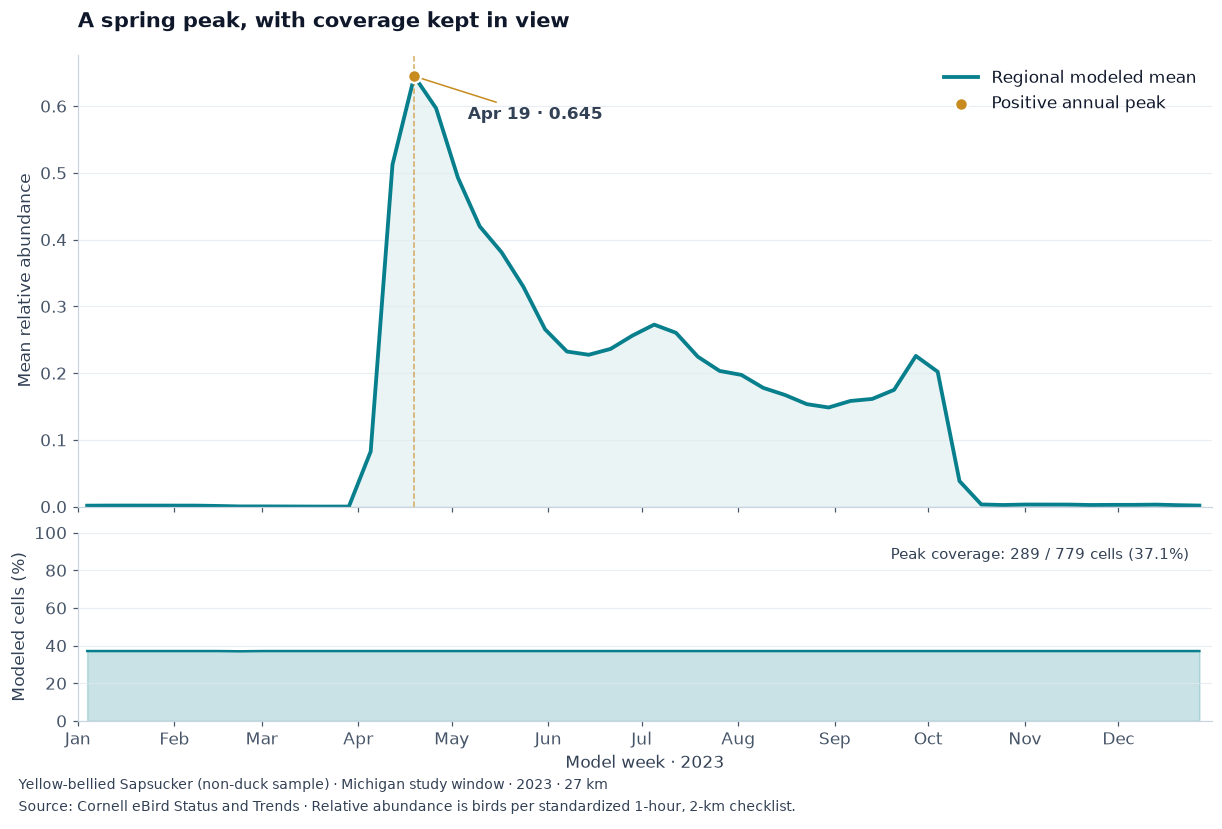

In [14]:
fig, (abundance_ax, coverage_ax) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1.25]}, layout="constrained",
)
abundance_ax.plot(curve.week_date, curve.mean_relative_abundance,
                  color=TEAL, linewidth=2.5, label="Regional modeled mean")
abundance_ax.fill_between(curve.week_date, curve.mean_relative_abundance, color=TEAL, alpha=0.08)
for i, row in peak.iterrows():
    abundance_ax.scatter(row.week_date, row.mean_relative_abundance,
                         s=70, color=GOLD, edgecolor="white", linewidth=1.5, zorder=5,
                         label="Positive annual peak" if i == 0 else None)
    abundance_ax.axvline(row.week_date, color=GOLD, linewidth=1, linestyle="--", alpha=0.7)
    abundance_ax.annotate(f"{row.week_date:%b %d} · {row.mean_relative_abundance:.3f}",
                          (row.week_date, row.mean_relative_abundance),
                          xytext=(35, -28), textcoords="offset points", color=SLATE,
                          arrowprops={"arrowstyle": "-", "color": GOLD}, weight="bold")
abundance_ax.set_ylim(bottom=0)
abundance_ax.set_ylabel("Mean relative abundance")
abundance_ax.set_title("A spring peak, with coverage kept in view", loc="left", weight="bold", pad=18)
abundance_ax.legend(loc="upper right", frameon=False)
abundance_ax.grid(axis="y", alpha=0.7)
coverage_ax.fill_between(curve.week_date, 100 * curve.coverage_fraction, color=TEAL, alpha=0.22)
coverage_ax.plot(curve.week_date, 100 * curve.coverage_fraction, color=TEAL, linewidth=1.6)
coverage_ax.set_ylim(0, 100)
coverage_ax.set_ylabel("Modeled cells (%)")
coverage_ax.grid(axis="y", alpha=0.7)
coverage_ax.xaxis.set_major_locator(mdates.MonthLocator())
coverage_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
coverage_ax.set_xlabel("Model week · 2023")
coverage_ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"))
first = peak.iloc[0]
coverage_ax.text(0.98, 0.86,
                 f"Peak coverage: {first.modeled_cell_count} / {first.selected_cell_count} cells ({first.coverage_fraction:.1%})",
                 transform=coverage_ax.transAxes, ha="right", color=SLATE, fontsize=10)
fig.text(0.01, -0.045,
         "Yellow-bellied Sapsucker (non-duck sample) · Michigan study window · 2023 · 27 km\n"
         "Source: Cornell eBird Status and Trends · Relative abundance is birds per standardized 1-hour, 2-km checklist.",
         fontsize=9, color=SLATE, linespacing=1.6)
show_chart(fig, "weekly-abundance.png")


The peak is **April 19, 2023** in this pinned sample. Only **289 of 779** selected
cell centers have predictions at the peak, about **37.1%**. The public raster is
restricted to Michigan, while the rectangular study window extends beyond it.
That coverage figure describes cell centers within the raster extent, not the
fraction of the polygon's area covered.

Do not turn the mean into a total population, and do not read missing predictions
as absence. When changing the study region or comparing datasets, inspect coverage
before interpreting a change in the abundance curve. The sample's season dates
also show why `wraps_year` matters: its nonbreeding season runs from November 22
through March 8 across New Year.


In [15]:
# Cross-check the calendar against the complete weekly curve before saving outputs.
assert len(curve) == 52 and curve.week_date.is_unique
assert curve.coverage_fraction.between(0, 1).all()
assert (curve.modeled_cell_count <= curve.selected_cell_count).all()
expected_peak = curve.loc[curve.mean_relative_abundance == curve.mean_relative_abundance.max(), "week_date"].tolist()
assert peak.week_date.tolist() == expected_peak
assert peak.week_date.dt.strftime("%Y-%m-%d").tolist() == ["2023-04-19"]
assert peak.modeled_cell_count.tolist() == [289]
assert peak.selected_cell_count.tolist() == [779]
assert abs(peak.mean_relative_abundance.iloc[0] - 0.6447039050788048) < 1e-12
%sql --close ducks_demo
engine.dispose()
extension_directory.cleanup()
print("Verified: 52 weeks, consistent peak, and explicit modeled-cell coverage.")


Verified: 52 weeks, consistent peak, and explicit modeled-cell coverage.


## Use the same queries for ducks

Obtain a [Status and Trends access key](https://ebird.org/st/request) and configure
`EBIRDST_KEY` before starting the notebook kernel, or create an `ebirdst` DuckDB
session secret. Keep credentials out of saved cells and outputs. This is separate
from the key used by the recent-sightings API.

Choose a duck species code available in the selected **model release** and replace
`yebsap-example` in the three function calls. The 2026 catalog code may differ
from the code used in a 2023 model. Replace `study_region` with your WGS84 polygon;
then compare the seasonal range joins, weekly curve, peak weeks, and coverage.
The checks in the final code cell validate this specific sample; adjust those
expected results when deliberately changing the dataset.

The worker also provides `recent_sightings` and `nearby_hotspots` with an eBird
API key. See the [README](../README.md) for their different scope and semantics.

### Reproducibility and sources

- [vgi-ducks v0.1.0](https://github.com/Query-farm/vgi-ducks/releases/tag/v0.1.0): pinned TypeScript worker release.
- [Taxonomy provenance](../data/README.md): the bundled eBird 2026 duck subset and extinction flags.
- [Cornell's public example data](https://github.com/ebird/ebirdst_example-data/tree/a3ab944f505ad6f583e0c830d5e951929446e9eb): the worker pins this exact revision.
- [eBird Status and Trends data semantics](https://ebird.github.io/ebirdst/articles/status.html): modeled abundance, seasonal products, and appropriate interpretation.
- [Verification record](../VERIFICATION.md): worker tests, independent spatial checks, and authenticated-access limitations.

Saved charts are embedded PNGs for GitHub's static notebook renderer. Interactive
widgets are unnecessary to read this demo. `scripts/render_notebook.py` reruns the
notebook and writes a local HTML preview to `dist/notebooks/`.
